Now, apply what you’ve learned. This version of the Selkov model is a simplified representation of
glycolytic oscillations:
$$\frac{dx}{dt} = -x + ay + x^2y$$
$$\frac{dy}{dt} = b - ay - x^2y$$
It is a dimensionless model where $x$ denotes the dimensionless substrate concentration and $y$ denotes the
dimensionless product concentration, and the dimensionless parameters $a$ and $b$ are non-negative. For a
biochemically more realistic glycolytic oscillator model, please look at Section 1.5 in the textbook.

In [17]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [18]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Selkov_Oscillator")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "a": 0.1,
    "b": 0.6,
}

# Define the ODEs.
varspecs = {
    'x': "-x + a*y + x^2*y",
    'y': "b - a*y - x^2*y",
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "x": 0.75,
    "y": 1.0,
}

# Define a domain for the variables, it is used when finding steady states, plotting null clines and vector fields.
domain = {
    'x': [-0.1, 2.0],
    'y': [-0.1, 2.0]}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...
Plotting trajectory...


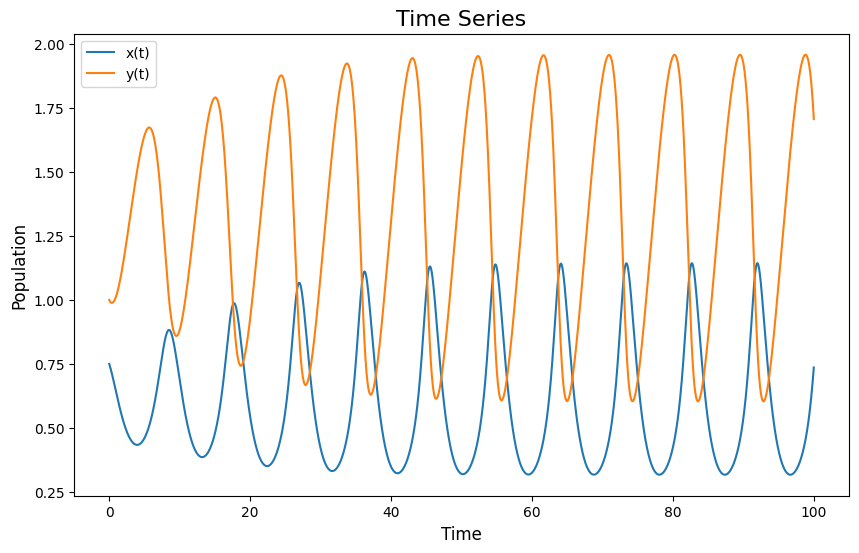

Plotting phase...
Plotting phase...


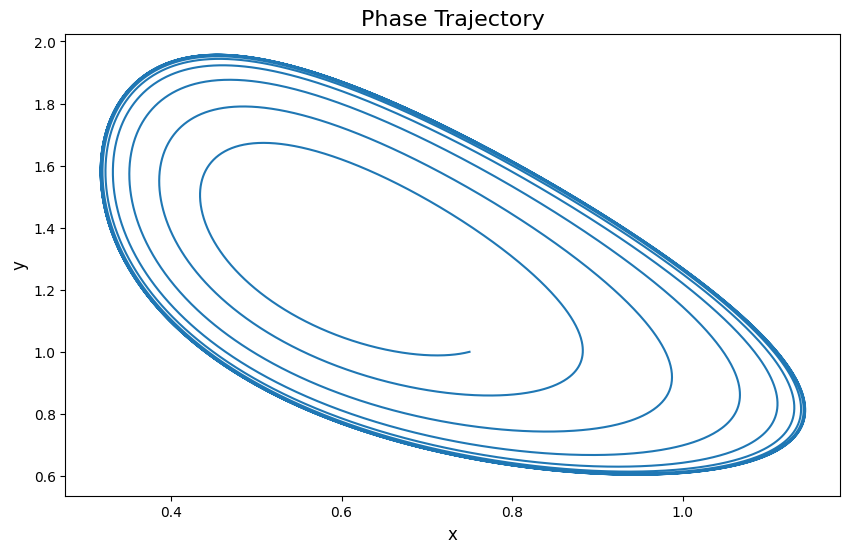

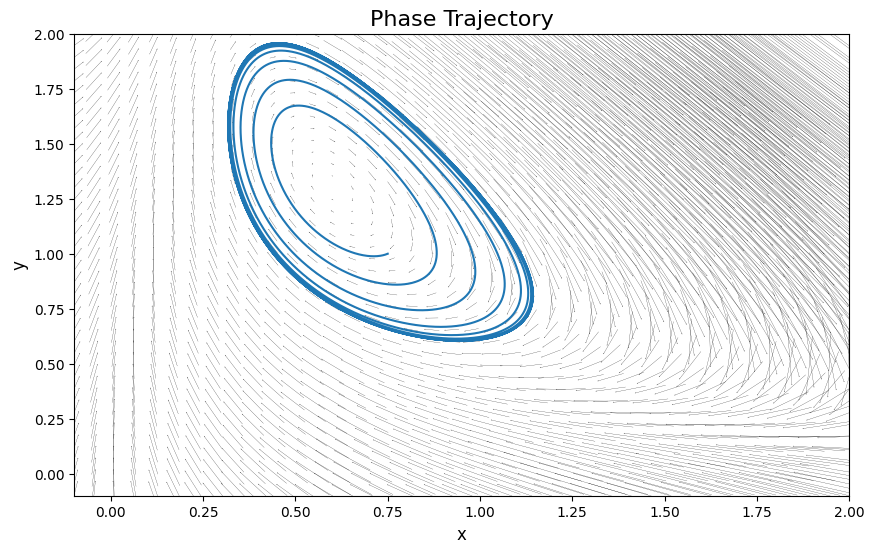

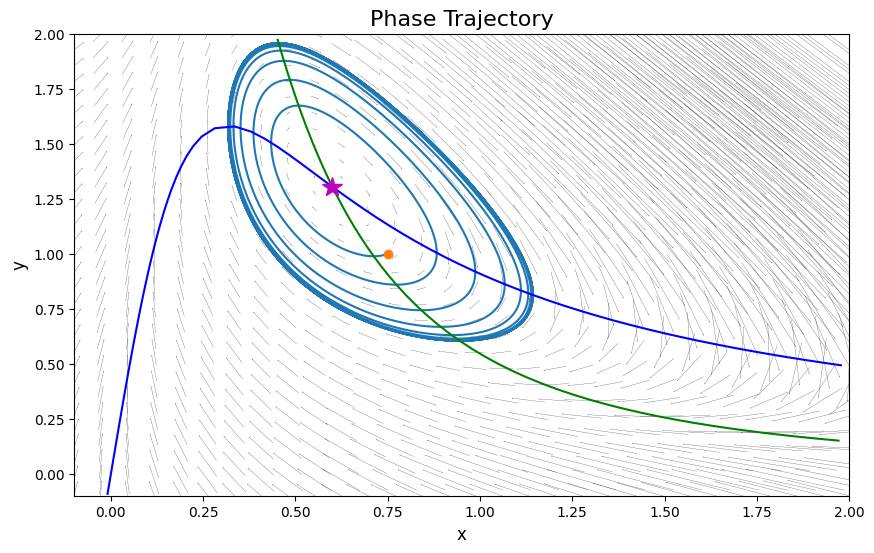

In [64]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 100])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# 3. Plot the trajectory
print("Plotting trajectory...")
fig_A, ax_A = plt.subplots(figsize=(10, 6))
ax_A.plot(points['t'], points['x'], label='x(t)')
ax_A.plot(points['t'], points['y'], label='y(t)')
ax_A.set_title('Time Series', fontsize=16)
ax_A.set_xlabel('Time', fontsize=12)
ax_A.set_ylabel('Population', fontsize=12)
plt.legend()

plt.show()

# 3. Plot the phase trajectory
print("Plotting phase...")
fig_B, ax_B = plt.subplots(figsize=(10, 6))
ax_B.plot(points['x'], points['y'], )
ax_B.set_title('Phase Trajectory', fontsize=16)
ax_B.set_xlabel('x', fontsize=12)
ax_B.set_ylabel('y', fontsize=12)

# 4. Plot the phase trajectory and vector field
print("Plotting phase...")
fig_C, ax_C = plt.subplots(figsize=(10, 6))
ax_C.plot(points['x'], points['y'], )
ax_C.set_title('Phase Trajectory', fontsize=16)
ax_C.set_xlabel('x', fontsize=12)
ax_C.set_ylabel('y', fontsize=12)

# Plot vector field, uses a scale exponent. Not a fan of the scale exponent, there is no option to normalise.
pp.plot_PP_vf(ode_sys, "x", "y", N=40, scale_exp=0)

plt.show()

# Find the nullclines and plot the complete phase portrait

# First find the SS (fixed points). It returns a list as there can be multiple fixed points.

fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]

# Now find the nullcline, giving the fixed points will help with convergence.
nulls_x, nulls_y = pp.find_nullclines(ode_sys, 'x', 'y', n=3, eps=1e-8, max_step=0.05, fps = [fp_coord])

fig_D, ax_D = plt.subplots(figsize=(10, 6))
ax_D.plot(points['x'], points['y'], )
ax_D.set_title('Phase Trajectory', fontsize=16)
ax_D.set_xlabel('x', fontsize=12)
ax_D.set_ylabel('y', fontsize=12)

# Plot vector field, uses a scale exponent. Not a fan of the scale exponent, there is no option to normalise. Preferably be done manually.
pp.plot_PP_vf(ode_sys, "x", "y", N=30, scale_exp=0)



# Plot the nullclines
plt.plot(nulls_x[:,0], nulls_x[:,1], 'b')
plt.plot(nulls_y[:,0], nulls_y[:,1], 'g')

# Plot the fixed point
ax_D.plot(fp_coord["x"], fp_coord["y"], 'm*', ms=15, label='Stable Steady State (0,0)')

# Plot the initial condition
ax_D.plot(ics["x"], ics["y"], marker="o", label="Initial condition")

plt.show()

In [28]:
# 3. Start Bifurcation Analysis
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

PyCont = dst.ContClass(ode_sys)
PCargs_EQ = dst.args(name='EQ1', type='EP-C')  # Equilibrium curve
PCargs_EQ.freepars = ['b'] # Parameter we want to bifurcate against
PCargs_EQ.MaxNumPoints = 200 # Maximum number of points, continuation will stop if exceeds this limit
PCargs_EQ.MaxStepSize = 1e-3 # Defines the maximum step size at each step of continuation, this is an important parameter and it will depend on the system
PCargs_EQ.MinStepSize = 1e-5 # Defines the minimum step size at each step of continuation. Depends on the system
PCargs_EQ.LocBifPoints = 'all' # Specifies the points to look for. If 'all' is given, will find any bifurcation point
PCargs_EQ.SaveEigen = True
PCargs_EQ.SaveJacobian = True
PCargs_EQ.verbosity = 2
PCargs_EQ.initpoint = fp_coord
PyCont.newCurve(PCargs_EQ)

# Forward and backward continuation
PyCont['EQ1'].forward()
PyCont['EQ1'].backward()

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  3.675338512513439e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000000

H Point found 
0 : 
x  =  0.7896877875922643
y  =  1.091321675734545
b  =  0.7896877875922643

Eigenvalues = 

     (-0.000000,0.850651)
     (-0.000000,-0.850651)


w = 0.8506508107514383
l1 = -0.398981597217686

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  1.7902944008846148e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000000

H Point found 
0 : 
x  =  0.419991902962605
y  =  1.5195450002374835
b  =  0.419991902962605

Eigenvalues = 

     (-0.000000,0.525731)
     (-0.000000,-0.525731)


w = 0.5257311085936953
l1 = -0.9168078763261575



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (b, x) space')

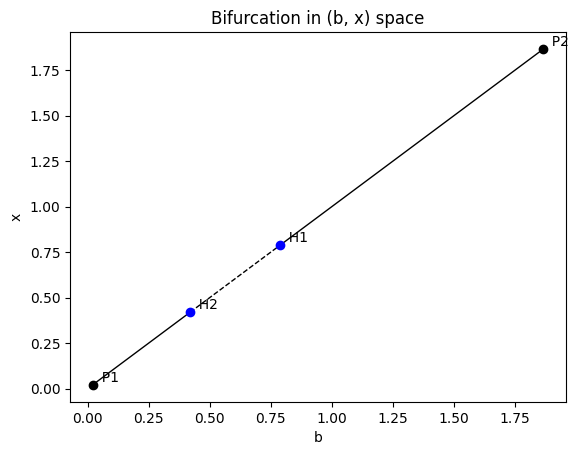

In [27]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
PyCont.display(('b', 'x'), stability=True)
plt.title("Bifurcation in (b, x) space")

In [60]:
# Since we have previously found hopf curves, we can perform a LCC (Limit cycle continuation) starting at H1.
PCargs_LC = dst.args(name='LC1', type='LC-C', force=True)
PCargs_LC.description = """One-parameter LC-C with b as free parameter starting at H1."""
PCargs_LC.freepars = ['b']
PCargs_LC.initpoint = 'EQ1:H1' # We want to start from the point H1 that in the curve EQ1 we defined previously.
PCargs_LC.MaxNumPoints   = 50
PCargs_LC.StepSize = 1e-3
PCargs_LC.MaxStepSize = 1e-1
PCargs_LC.MinStepSize = 1e-4 
PCargs_LC.NumSPOut = 100
PCargs_LC.LocBifPoints = 'all'
PCargs_LC.SolutionMeasures = 'all'
PCargs_LC.SaveEigen = True
PCargs_EQ.verbosity = 2
PyCont.newCurve(PCargs_LC)

print('Computing LC-C at H1...')
start = dst.perf_counter()
PyCont['LC1'].forward()
print('done in %.3f seconds!' % (dst.perf_counter()-start))

Computing LC-C at H1...
 
  BR    PT  TY LAB    PAR(1)        L2-NORM       MAX(1)        MAX(2)         PERIOD    
   1    49  LP   2  4.199919E-01  1.576518E+00  4.200346E-01  1.519637E+00  1.195133E+01
   1    50  EP   3  4.208656E-01  1.575643E+00  4.524712E-01  1.582534E+00  1.193780E+01
done in 0.019 seconds!


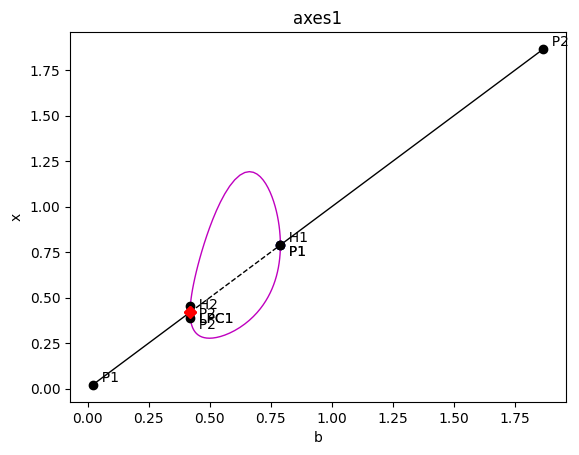

In [61]:
# Plot the results
PyCont.display(('b','x'), stability=True)
PyCont['LC1'].display(('b','x_min'), stability=True)